<a href="https://colab.research.google.com/github/oliviaaghamie/insulin-conservation-12-species/blob/main/notebook/Insulin_Conservation_Across_12_Species.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cross-Species Conservation of Insulin: Comparing Functional Chains and the C-Peptide Across 12 Animals

**Student Name:** Olivia Aghamie  
**Student ID:** 1002095139  

**Question:** How similar is insulin to the human sequence across 11 animals,
and are the A and B chains of the mature hormone more conserved than the
C-peptide that is removed when insulin is made?




## What that means, in plain words

The body does not make insulin in its finished form. It makes one long chain of **110 amino acids**. Think of them as 110 letters, cut into four pieces:

| Letters | Piece | What it does | What happens to it |
|---|---|---|---|
| 1–24 | Signal peptide | A shipping label that tells the cell where to send the chain | Cut off |
| 25–54 | **B chain** | Half of the working hormone | **Kept** |
| 57–87 | C-peptide | A spacer that holds the A and B chains in position while they are joined | Cut out |
| 90–110 | **A chain** | The other half of the working hormone | **Kept** |

The numbers skip from 54 to 57 and from 87 to 90. Those four letters are cutting sites, and they belong to no region.

Two disulfide bonds connect the A and B chains, and a third sits inside the A chain (Vinther et al., 2013). The joined A and B chains are the mature hormone, 51 letters long. The C-peptide is cut out when the mature hormone forms. Being removed does not mean the C-peptide has no biological importance.

## Why there should be a pattern to find

The A and B chains have to fit the insulin receptor. A change there can alter the shape of the hormone, so fewer of those changes get passed on. The C-peptide is cut out before insulin acts, so more changes there are expected to be tolerated.

Over hundreds of millions of years, that difference should show up: the A and B chains should stay more similar between species than the C-peptide. **This notebook tests whether that is true for 12 animals.**

## Why it matters outside the computer

Before lab-made human insulin arrived in 1982, diabetes was treated with insulin from pig and cow pancreas. Pig insulin differs from human insulin at **one position** in the mature hormone, and cow insulin at three (Yang et al., 2025).

### Step 1 — Download and align

This code downloads one insulin sequence for each of the 12 animals from UniProt and
aligns them with MAFFT.

The sequences differ in length: human is 110 amino acids, cow is 105. Alignment puts
matching amino acids in the same column and fills the gaps with dashes. Illustration:

```
Human  ... G A G S L Q P L A L E G S L Q ...
Cow    ... G A G - - - - - L A L E G S L Q ...
```

The dashes shift the column numbers. Step 2 deals with that.

In [1]:
import requests

animals = {
    "Human": "P01308", "Chimpanzee": "P30410", "Pig": "P01315", "Cow": "P01317",
    "Sheep": "P01318", "Dog": "P01321", "Cat": "P06306", "Rabbit": "P01311",
    "Mouse": "P01326", "Guinea_pig": "P01329", "Chicken": "P67970", "Zebrafish": "O73727",
}

with open("insulin_12_animals.fasta", "w") as out:
    for animal, accession in animals.items():
        reply = requests.get(f"https://rest.uniprot.org/uniprotkb/{accession}.fasta", timeout=60)
        reply.raise_for_status()
        sequence = "".join(reply.text.strip().splitlines()[1:])
        out.write(f">{animal}|{accession}\n{sequence}\n")
print("downloaded", len(animals), "sequences")

!apt-get -qq install -y mafft
!mafft --auto insulin_12_animals.fasta > insulin_aligned.fasta
print("alignment written to insulin_aligned.fasta")

downloaded 12 sequences
Extracting templates from packages: 100%
Selecting previously unselected package fonts-lato.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../00-fonts-lato_2.015-1_all.deb ...
Unpacking fonts-lato (2.015-1) ...
Selecting previously unselected package libclone-perl:amd64.
Preparing to unpack .../01-libclone-perl_0.46-1build3_amd64.deb ...
Unpacking libclone-perl:amd64 (0.46-1build3) ...
Selecting previously unselected package libdata-dump-perl.
Preparing to unpack .../02-libdata-dump-perl_1.25-1_all.deb ...
Unpacking libdata-dump-perl (1.25-1) ...
Selecting previously unselected package libencode-locale-perl.
Preparing to unpack .../03-libencode-locale-perl_1.05-3_all.deb ...
Unpacking libencode-locale-perl (1.05-3) ...
Selecting previously unselected package libhttp-date-perl.
Preparing to unpack .../04-libhttp-date-perl_6.06-1ubuntu0.24.04.1_all.deb ...
Unpacking libhttp-date-perl (6.06-1ubuntu0.24.04.1) ...
Selec

**Output**

All 12 sequences downloaded. The alignment is 117 columns wide, and the human row
contains 7 dashes.

Each dash shifts every later position one column to the right, so column numbers do not
match human positions. Reading columns 25–54 as the B chain would measure the wrong amino
acids. My professor flagged this in his feedback on my proposal. Step 2 fixes it.

### Software versions

Versions used, for reproducibility. MUSCLE is installed in Step 4, which prints its version.

In [2]:
import sys, pandas, matplotlib, requests
print("Python     ", sys.version.split()[0])
print("pandas     ", pandas.__version__)
print("matplotlib ", matplotlib.__version__)
print("requests   ", requests.__version__)
!mafft --version

Python      3.13.18
pandas      2.2.3
matplotlib  3.10.0
requests    2.32.4
v7.505 (2022/Apr/10)


## Step 2 — Map human positions, then measure

**Mapping.** The code walks along the aligned human row, counts amino acids and skips
dashes. It records the column of every human position. Each region boundary is looked up
through this map.

**Testing the map.** The code uses the map to pull the B and A chains out of the human
row. The output should match the known human B and A chain sequences exactly.

**Measuring.** For each animal and each region, the code counts the columns that match
human and converts the count to percent identity. A dash counts as a mismatch.Columns where human has a dash are not scored. Step 5
tests whether that choice affects the result.

**Two checks:**

- **Check 1 — known answer.** Published work reports that pig insulin differs from human
  at one position in the mature hormone and cow at three (Yang et al., 2025). These values
  come from outside this project, and the code has to reproduce them.
- **Check 2 — structural prediction.** Six cysteines form the three disulfide bonds that
  hold insulin together. These bonds hold insulin's shape, so these six positions should be identical in all 12 species.

In [3]:
import pandas as pd

REGIONS = {"Signal peptide": (1, 24), "B chain": (25, 54),
           "C-peptide": (57, 87), "A chain": (90, 110)}

def read_fasta(path):
    seqs, name = {}, None
    for line in open(path):
        line = line.strip()
        if line.startswith(">"):
            name = line[1:].split("|")[0]
            seqs[name] = ""
        elif name:
            seqs[name] += line
    return seqs

aligned = read_fasta("insulin_aligned.fasta")
human = aligned["Human"]
print("alignment width:", len(human), "columns | gaps in human row:", human.count("-"))

# the lookup table: human residue number -> alignment column
position_to_column, residue = {}, 0
for column, letter in enumerate(human):
    if letter != "-":
        residue += 1
        position_to_column[residue] = column

region_columns = {name: [position_to_column[p] for p in range(a, b + 1)]
                  for name, (a, b) in REGIONS.items()}
mature_columns = region_columns["B chain"] + region_columns["A chain"]

# proof the lookup works: these must be the real human region sequences
print("B chain reads as:", "".join(human[c] for c in region_columns["B chain"]))
print("A chain reads as:", "".join(human[c] for c in region_columns["A chain"]))

def identity(row, columns):
    return 100.0 * sum(1 for c in columns if row[c] == human[c]) / len(columns)

rows = []
for animal, row in aligned.items():
    if animal == "Human":
        continue
    entry = {"Animal": animal.replace("_", " ")}
    for name in REGIONS:
        entry[name] = round(identity(row, region_columns[name]), 1)
    entry["Mature hormone"] = round(identity(row, mature_columns), 1)
    entry["Mature differences"] = sum(1 for c in mature_columns if row[c] != human[c])
    rows.append(entry)

results = pd.DataFrame(rows).sort_values("Mature hormone", ascending=False)
results.to_csv("results.csv", index=False)
print()
print(results.to_string(index=False))

# --- known-answer checks ---
print("\nCHECK 1 (published values: pig 1, cow 3)")
for animal in ["Pig", "Cow"]:
    n = results.loc[results.Animal == animal, "Mature differences"].item()
    print(f"  {animal}: {n} differences", "PASS" if n == {"Pig":1,"Cow":3}[animal] else "FAIL")

cys = [p for p in range(1, 111) if human[position_to_column[p]] == "C"]
print("\nCHECK 2 — cysteines at human positions", cys)
for p in cys:
    letters = {aligned[a][position_to_column[p]] for a in aligned}
    print(f"  position {p}: {'conserved in all 12' if letters == {'C'} else 'NOT conserved -> ' + str(letters)}")

alignment width: 117 columns | gaps in human row: 7
B chain reads as: FVNQHLCGSHLVEALYLVCGERGFFYTPKT
A chain reads as: GIVEQCCTSICSLYQLENYCN

    Animal  Signal peptide  B chain  C-peptide  A chain  Mature hormone  Mature differences
Chimpanzee            91.7    100.0      100.0    100.0           100.0                   0
       Pig            83.3     96.7       64.5    100.0            98.0                   1
       Dog            83.3     96.7       74.2    100.0            98.0                   1
    Rabbit            62.5     96.7       77.4    100.0            98.0                   1
       Cow            79.2     96.7       54.8     90.5            94.1                   3
     Sheep            79.2     96.7       54.8     85.7            92.2                   4
       Cat            70.8     96.7       67.7     85.7            92.2                   4
     Mouse            70.8     90.0       71.0     95.2            92.2                   4
   Chicken            62.5    

**Output**

The map works. The B and A chains read out as the exact human sequences.

The mature hormone is closer to human than the C-peptide in 9 of 11 animals, by 20.6 to
63.7 percentage points. This matches the prediction.

Two animals break the pattern:
- **Chimpanzee** is 100% identical to human in both regions.
- **Guinea pig** is reversed. Its C-peptide is 71.0% identical to human and its mature
  hormone is 64.7%. Step 3 looks at this.

**Both checks pass.** Pig differs from human at 1 position in the mature hormone and cow
at 3, matching the published values. All six cysteines are identical in all 12 species.

These are counts. The published work also names the positions, and Step 5 checks those.

## Step 3 — Plot the comparison

For each animal, the plot shows mature hormone identity (blue) and C-peptide identity
(red), joined by a line. My professor suggested this plot so the main comparison is
visible at a glance.

The prediction is that every line runs downward, with blue above red. A line running the
other way is an exception and is drawn in red.

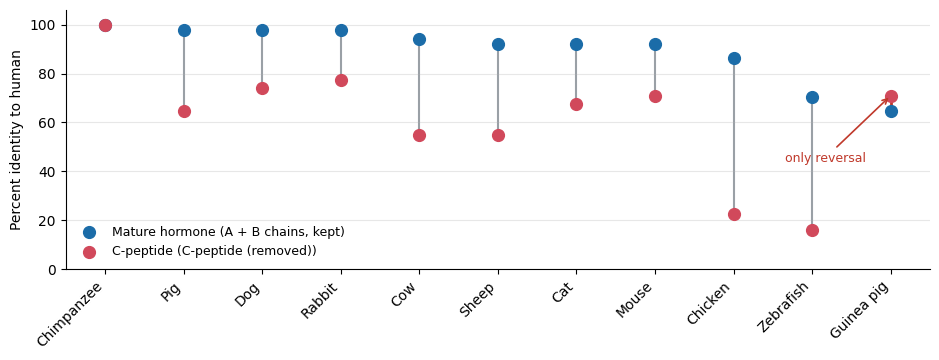

In [5]:
import matplotlib.pyplot as plt

ranked = results.sort_values("Mature hormone", ascending=False)
names  = list(ranked["Animal"]); mature = list(ranked["Mature hormone"])
cpep   = list(ranked["C-peptide"]); x = range(len(names))

fig, ax = plt.subplots(figsize=(9.5, 3.7))
for i in x:
    reversed_pair = cpep[i] > mature[i]
    ax.plot([i, i], [cpep[i], mature[i]],
            color="#c0392b" if reversed_pair else "#9aa0a6",
            linewidth=2 if reversed_pair else 1.5, zorder=1)
ax.scatter(x, mature, s=72, color="#1b6ca8", zorder=3, label="Mature hormone (A + B chains, kept)")
ax.scatter(x, cpep,   s=72, color="#d1495b", zorder=3, label="C-peptide (C-peptide (removed))")
ax.annotate("only reversal", xy=(len(names)-1, cpep[-1]), xytext=(len(names)-2.35, 44),
            fontsize=9, color="#c0392b",
            arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.2))
ax.set_xticks(list(x)); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_ylabel("Percent identity to human"); ax.set_ylim(0, 106)
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig("figure1_paired_plot.png", dpi=200)
plt.show()

**Output**

Every grey line runs downward. The one red line is guinea pig.

**Guinea pig breaks the pattern.** Mouse, another rodent, is at 92.2%. Guinea pig is at 64.7%, lower than zebrafish (70.6%).

**Pipeline check.** Both checks passed on this alignment, and guinea pig is the only
animal with this pattern.These checks support the result. They do not rule out every possible error.

**Literature.** Guinea pigs are caviomorph rodents, and insulin in this group is known
to be unusual. Opazo et al. (2005) call caviomorph
insulin "a very divergent molecule with unusual physiological properties".

Guinea pig insulin still works despite 18 changes in the mature hormone. Step 5 checks
where those changes fall.

## Step 4 — Repeat with a second aligner

This code aligns the same 12 sequences with MUSCLE, a different alignment program,
repeats the Step 2 measurement, and subtracts the MAFFT results from the MUSCLE results.

MAFFT and MUSCLE place gaps differently, so the two alignments can differ in width and
gap position. Each alignment gets its own position map, so both are measured at the same
human positions. A table of zeros means the result does not depend on the aligner.

In [6]:
!apt-get -qq install -y muscle
!muscle -in insulin_12_animals.fasta -out insulin_muscle.fasta 2>/dev/null || muscle -align insulin_12_animals.fasta -output insulin_muscle.fasta

def analyse(path):
    """Run the Step 2 measurement on any alignment file, using its own ruler."""
    aln = read_fasta(path)
    ref = aln["Human"]
    pos, residue = {}, 0
    for column, letter in enumerate(ref):
        if letter != "-":
            residue += 1
            pos[residue] = column
    cols = {n: [pos[p] for p in range(a, b + 1)] for n, (a, b) in REGIONS.items()}
    mature = cols["B chain"] + cols["A chain"]
    out = []
    for animal, row in aln.items():
        if animal == "Human":
            continue
        e = {"Animal": animal.replace("_", " ")}
        for n in REGIONS:
            e[n] = round(100.0 * sum(1 for c in cols[n] if row[c] == ref[c]) / len(cols[n]), 1)
        e["Mature hormone"] = round(100.0 * sum(1 for c in mature if row[c] == ref[c]) / len(mature), 1)
        out.append(e)
    return pd.DataFrame(out).set_index("Animal").sort_index(), len(ref), ref.count("-")

mafft_table,  mafft_width,  mafft_gaps  = analyse("insulin_aligned.fasta")
muscle_table, muscle_width, muscle_gaps = analyse("insulin_muscle.fasta")

print(f"MAFFT  : {mafft_width} columns, {mafft_gaps} gaps in the human row")
print(f"MUSCLE : {muscle_width} columns, {muscle_gaps} gaps in the human row")

difference = (muscle_table - mafft_table).round(1)
print("\nMUSCLE minus MAFFT (0.0 everywhere means the two programs agree):")
print(difference.to_string())

biggest = difference.abs().max().max()
print(f"\nLargest disagreement anywhere in the table: {biggest} percentage points")
print("CHECK 3 PASSED: the two aligners give identical percentages."
      if biggest == 0 else "The two aligners differ. Report where, and by how much.")

Selecting previously unselected package muscle.
(Reading database ... 126734 files and directories currently installed.)
Preparing to unpack .../muscle_1%3a5.1.0-1_amd64.deb ...
Unpacking muscle (1:5.1.0-1) ...
Setting up muscle (1:5.1.0-1) ...
Processing triggers for man-db (2.12.0-4build2) ...

muscle 5.2.linux64 [-]  13.3Gb RAM, 2 cores
Built Nov  5 2022 18:45:38
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 12 seqs, avg length 109, max 110

00:00 9.1Mb  CPU has 2 cores, running 2 threads
00:00 85Mb    100.0% Calc posteriors
00:00 85Mb    100.0% Consistency (1/2)
00:00 85Mb    100.0% Consistency (2/2)
00:00 85Mb    100.0% UPGMA5
00:00 85Mb    100.0% Refining
MAFFT  : 117 columns, 7 gaps in the human row
MUSCLE : 112 columns, 2 gaps in the human row

MUSCLE minus MAFFT (0.0 everywhere means the two programs agree):
            Signal peptide  B chain  C-peptide  A chain  Mature hormone
Animal                                                                 
Cat  

**Output**

MAFFT: 117 columns, 7 gaps in the human row. MUSCLE: 112 columns, 2 gaps in the human row.

The two programs give identical percent identities for the signal peptide, B chain,
A chain and mature hormone in all 11 animals. They differ only in the C-peptide, for
two animals:

- Chicken: 22.6% (MAFFT), 19.4% (MUSCLE)
- Zebrafish: 16.1% (MAFFT), 9.7% (MUSCLE)

On a 31-position region, that is one amino acid for chicken and two for zebrafish. The
C-peptide varies in length between species, so it is where the aligners place gaps.
Chicken and zebrafish are the most distant species in the set.

**Check 3.** The strict test in the code, zeros everywhere, does not pass because of
these two C-peptide differences. The mature hormone, which carries the main result, is
identical under both programs. Two alignments of different widths giving the same region
values also supports that the position map works. I report the MAFFT values, which give the
smaller gap between the two regions.

## Step 5 — Follow-up questions

The earlier steps left three questions:

1. **Which positions differ?** Step 2 reported counts. The published work also names the
   pig and cow positions and the amino acid changes. Naming them is a stricter version
   of check 1.
2. **Where do the guinea pig's changes fall?** Insulin binds its receptor through two
   known sets of residues: site 1, the classical binding surface, and site 2 (Ward &
   Lawrence, 2011). This step counts how many guinea pig changesfall in each site. I added this question after seeing the guinea pig result.
3. **Does the gap choice matter? (check 4)** Step 2 counts a dash as a mismatch. This
   step repeats the measurement with gap columns removed.

The same code produces Figure 2 and Figure 3.

In [7]:
# --- Step 5a: name the differences, check the binding surface, redo without gaps ---

def label(p):
    """Human precursor position -> standard insulin numbering (B30, A8, C12 ...)."""
    if 1  <= p <= 24:  return f"S{p}"
    if 25 <= p <= 54:  return f"B{p - 24}"
    if 57 <= p <= 87:  return f"C{p - 56}"
    if 90 <= p <= 110: return f"A{p - 89}"
    return f"link{p}"

# Residues forming the insulin receptor binding surfaces (Ward & Lawrence, 2011)
SITE_1 = {"A1","A2","A3","A5","A8","A19","A21","B12","B16","B23","B24","B25","B26"}
SITE_2 = {"A12","A13","A17","B10","B13","B17"}

mature_positions = [p for p in list(range(25, 55)) + list(range(90, 111))]

print("DIFFERENCES FROM HUMAN IN THE MATURE HORMONE, BY POSITION")
print("(* = receptor binding site 1, + = site 2)\n")
binding_hits = {}
for animal in results["Animal"]:
    key = animal.replace(" ", "_")
    row = aligned[key]
    named, in_site = [], 0
    for p in mature_positions:
        c = position_to_column[p]
        if row[c] != human[c]:
            tag = "*" if label(p) in SITE_1 else ("+" if label(p) in SITE_2 else "")
            if tag:
                in_site += 1
            named.append(f"{label(p)}{tag} {human[c]}->{row[c]}")
    binding_hits[animal] = (in_site, len(named))
    shown = ", ".join(named) if named else "none"
    print(f"{animal:11s} ({len(named):2d}): {shown}")

print("\nHow many differences land on a receptor binding residue:")
for animal, (hits, total) in binding_hits.items():
    if total:
        print(f"  {animal:11s} {hits} of {total}")

# --- the same measurement with gap columns excluded ---
def identity_nogap(row, columns):
    usable = [c for c in columns if row[c] != "-"]
    return float("nan") if not usable else 100.0 * sum(1 for c in usable if row[c] == human[c]) / len(usable)

mature_cols = region_columns["B chain"] + region_columns["A chain"]
rows2 = []
for animal in results["Animal"]:
    row = aligned[animal.replace(" ", "_")]
    rows2.append({"Animal": animal,
                  "C-peptide (gaps=mismatch)": round(identity(row, region_columns["C-peptide"]), 1),
                  "C-peptide (gaps excluded)": round(identity_nogap(row, region_columns["C-peptide"]), 1),
                  "Mature (gaps=mismatch)": round(identity(row, mature_cols), 1),
                  "Mature (gaps excluded)": round(identity_nogap(row, mature_cols), 1)})
nogap = pd.DataFrame(rows2)
print("\nDOES THE 'A DASH COUNTS AS A MISMATCH' DECISION CHANGE THE ANSWER?\n")
print(nogap.to_string(index=False))

still_holds = sum(1 for r in rows2 if r["Mature (gaps excluded)"] > r["C-peptide (gaps excluded)"])
print(f"\nMature hormone still more conserved than the C-peptide in {still_holds} of {len(rows2)} animals"
      " when gap columns are excluded.")

# --- chance check: how many guinea pig changes would land in site 1 at random? ---
from math import comb
gp_row = aligned["Guinea_pig"]
gp_changed = [p for p in mature_positions if gp_row[position_to_column[p]] != human[position_to_column[p]]]
gp_site1 = sum(1 for p in gp_changed if label(p) in SITE_1)
N, K, n = len(mature_positions), len(SITE_1), len(gp_changed)
expected = n * K / N
p_value = sum(comb(K, i) * comb(N - K, n - i) for i in range(gp_site1 + 1)) / comb(N, n)
print(f"\nGuinea pig: {gp_site1} of {n} mature hormone changes in site 1")
print(f"Expected by chance: {expected:.1f}")

DIFFERENCES FROM HUMAN IN THE MATURE HORMONE, BY POSITION
(* = receptor binding site 1, + = site 2)

Chimpanzee  ( 0): none
Pig         ( 1): B30 T->A
Dog         ( 1): B30 T->A
Rabbit      ( 1): B30 T->S
Cow         ( 3): B30 T->A, A8* T->A, A10 I->V
Sheep       ( 4): B30 T->A, A8* T->A, A9 S->G, A10 I->V
Cat         ( 4): B30 T->A, A8* T->A, A10 I->V, A18 N->H
Mouse       ( 4): B3 N->K, B29 K->M, B30 T->S, A4 E->D
Chicken     ( 7): B1 F->A, B2 V->A, B27 T->S, B30 T->A, A8* T->H, A9 S->N, A10 I->T
Zebrafish   (15): B1 F->G, B2 V->T, B3 N->P, B13+ E->D, B21 E->P, B22 R->T, B27 T->N, B30 T->-, A8* T->H, A9 S->K, A10 I->P, A13+ L->I, A14 Y->F, A15 Q->E, A17+ E->Q
Guinea pig  (18): B3 N->S, B4 Q->R, B10+ H->N, B14 A->T, B17+ L->S, B20 G->Q, B21 E->D, B22 R->D, B27 T->I, B30 T->D, A4 E->D, A9 S->G, A10 I->T, A12+ S->T, A13+ L->R, A14 Y->H, A17+ E->Q, A18 N->S

How many differences land on a receptor binding residue:
  Pig         0 of 1
  Dog         0 of 1
  Rabbit      0 of 1
  Cow      

**Output**

**Check 1, by position.** Pig differs from human at B30 (Thr→Ala). Cow differs at B30
(Thr→Ala), A8 (Thr→Ala) and A10 (Ile→Val). These are the positions and substitutions
reported by Yang et al. (2025).

**Guinea pig and the binding sites.** None of the guinea pig's 18 mature hormone changes
falls in site 1, and five fall in site 2. Guinea pig insulin has changed
across the mature hormone everywhere except the main receptor binding surface. This describes the sequence. It does not test receptor binding.

**Check 4.** With gap columns removed, the mature hormone is still closer to human than
the C-peptide in 9 of 11 animals. The only mature hormone value that changes is zebrafish
(70.6% to 72.0%), because zebrafish has a gap at B30.

### Figure 2 — Heatmap by region

The results table from Step 2 as a heatmap. Blue is high identity to human, red is low.

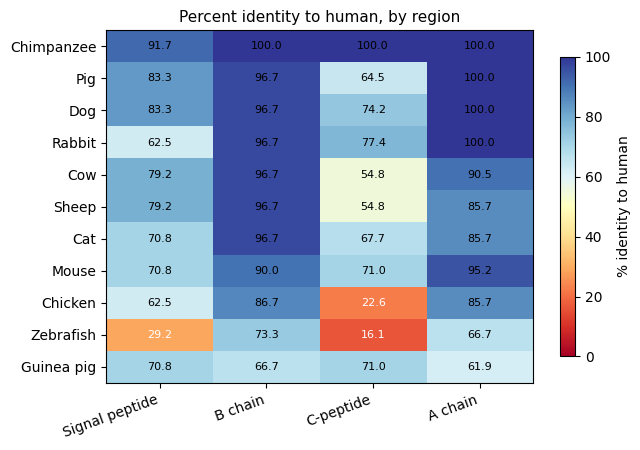

In [8]:
# --- Step 5b: Figure 2, heatmap of every animal against every region ---
import numpy as np

order = ["Signal peptide", "B chain", "C-peptide", "A chain"]
mat = results.set_index("Animal")[order]

fig, ax = plt.subplots(figsize=(6.6, 4.6))
im = ax.imshow(mat.values, cmap="RdYlBu", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=20, ha="right")
ax.set_yticks(range(len(mat)));   ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if v < 45 else "black")
ax.set_title("Percent identity to human, by region", fontsize=11)
fig.colorbar(im, ax=ax, label="% identity to human", shrink=0.85)
fig.tight_layout()
fig.savefig("figure2_heatmap.png", dpi=200)
plt.show()

**Output**

In 9 of 11 rows, the C-peptide is lower than both the B chain and the A chain.
Chimpanzee is 100% in all three. Guinea pig is the reverse, with the C-peptide above both
chains.

The signal peptide is also low in most rows. It is removed as well.

### Figure 3 — Variation by position

For each of the 106 positions, the number of animals (out of 11) that differ from human.
Bars are coloured by region. The code also lists the positions identical in all 12 species.

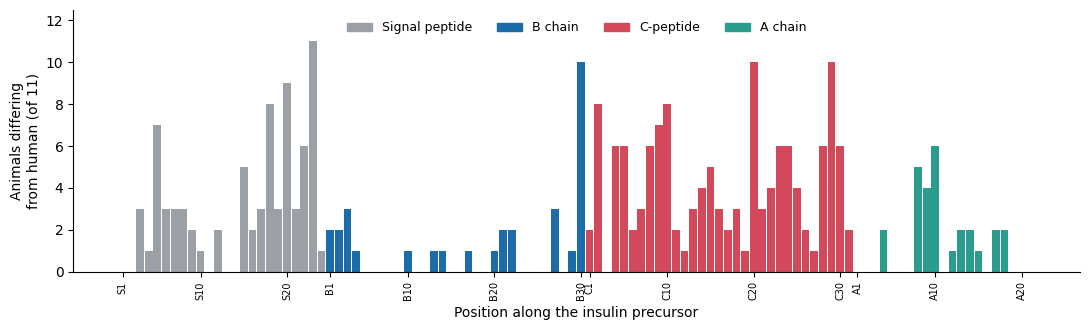

33 positions are identical in all 12 species:
  S1, S2, S11, S13, S14, B5, B6, B7, B8, B9, B11, B12, B15, B16, B18, B19, B23, B24, B25, B26, B28, C3, A1, A2, A3, A5, A6, A7, A11, A16, A19, A20, A21


In [9]:
# --- Step 5c: Figure 3, where along the molecule the differences fall ---
counts, colours, labels_x = [], [], []
palette = {"Signal peptide": "#9aa0a6", "B chain": "#1b6ca8",
           "C-peptide": "#d1495b", "A chain": "#2a9d8f"}

for region, (a, b) in REGIONS.items():
    for p in range(a, b + 1):
        c = position_to_column[p]
        differing = sum(1 for an in aligned if an != "Human" and aligned[an][c] != human[c])
        counts.append(differing); colours.append(palette[region]); labels_x.append(label(p))

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(len(counts)), counts, color=colours, width=0.9)
ax.set_ylabel("Animals differing\nfrom human (of 11)")
ax.set_xlabel("Position along the insulin precursor")
ticks = [i for i, l in enumerate(labels_x)
         if (lambda n: n == 1 or n % 10 == 0)(int(l[1:]))]
ax.set_xticks(ticks)
ax.set_xticklabels([labels_x[i] for i in ticks], rotation=90, fontsize=7)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), frameon=False, ncol=4, fontsize=9, loc="upper center")
ax.set_ylim(0, 12.5)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("figure3_positions.png", dpi=200)
plt.show()

perfect = [labels_x[i] for i, n in enumerate(counts) if n == 0]
print(f"{len(perfect)} positions are identical in all 12 species:")
print(" ", ", ".join(perfect))

**Output**

The C-peptide (red) has the most variation. The B chain (blue) and A chain (green) have
the least.

33 positions are identical in all 12 species:

| Region | Identical in all 12 |
|---|---|
| B chain | 16 of 30 (53%) |
| A chain | 11 of 21 (52%) |
| Signal peptide | 5 of 24 (21%) |
| C-peptide | 1 of 31 (3%) |

All six cysteines are in this list, as check 2 predicted.

**B30.** B30 is the most variable position in the mature hormone. Ten of 11 animals
differ from human there, and only chimpanzee matches. Pig insulin differs from human only
at B30.

### Aligner disagreement by position

Step 4 compared percentages. This lists every position where MAFFT and MUSCLE place a
different amino acid.

In [10]:
# --- Step 5d: exactly where MAFFT and MUSCLE disagree ---
muscle_aln = read_fasta("insulin_muscle.fasta")
muscle_human = muscle_aln["Human"]
muscle_pos, residue = {}, 0
for column, letter in enumerate(muscle_human):
    if letter != "-":
        residue += 1
        muscle_pos[residue] = column

print("Positions where the two aligners put a different residue:\n")
any_diff = False
for animal in aligned:
    if animal == "Human":
        continue
    rows_out = []
    for p in range(1, 111):
        a = aligned[animal][position_to_column[p]]
        b = muscle_aln[animal][muscle_pos[p]]
        if a != b:
            rows_out.append(f"{label(p)}: MAFFT {a} / MUSCLE {b}")
    if rows_out:
        any_diff = True
        print(f"{animal.replace('_',' ')}: " + "; ".join(rows_out))
if not any_diff:
    print("None - the two alignments agree at every human position.")

Positions where the two aligners put a different residue:

Pig: C15: MAFFT - / MUSCLE G; C16: MAFFT - / MUSCLE L; C17: MAFFT G / MUSCLE -; C18: MAFFT L / MUSCLE -
Chicken: C10: MAFFT P / MUSCLE -; C11: MAFFT L / MUSCLE P; C12: MAFFT R / MUSCLE L; C13: MAFFT G / MUSCLE R; C14: MAFFT - / MUSCLE G; C15: MAFFT - / MUSCLE E; C16: MAFFT - / MUSCLE A; C17: MAFFT E / MUSCLE G; C18: MAFFT A / MUSCLE V; C19: MAFFT G / MUSCLE L; C20: MAFFT V / MUSCLE P; C21: MAFFT L / MUSCLE F; C22: MAFFT P / MUSCLE -; C23: MAFFT F / MUSCLE -
Zebrafish: S20: MAFFT S / MUSCLE -; S21: MAFFT T / MUSCLE S; S22: MAFFT N / MUSCLE T; S23: MAFFT - / MUSCLE N; C7: MAFFT - / MUSCLE L; C8: MAFFT - / MUSCLE G; C9: MAFFT - / MUSCLE F; C10: MAFFT - / MUSCLE L; C11: MAFFT - / MUSCLE P; C12: MAFFT L / MUSCLE P; C13: MAFFT G / MUSCLE K; C14: MAFFT F / MUSCLE S; C15: MAFFT L / MUSCLE E; C16: MAFFT P / MUSCLE T; C17: MAFFT P / MUSCLE E; C18: MAFFT K / MUSCLE V; C19: MAFFT S / MUSCLE A; C20: MAFFT A / MUSCLE D; C21: MAFFT Q / MUSCLE

**Output**

The aligners disagree at 4 positions in pig, 14 in chicken and 26 in zebrafish. That is
more than the percent differences in Step 4 suggest. Moving one gap shifts a run of amino
acids, which changes many positions while the number matching human stays nearly the
same. Pig shows this: 4 positions differ, and its C-peptide identity is the same under
both aligners.

Every disagreement is in the C-peptide or signal peptide, and none is in the B chain or
A chain. Both aligners place every mature hormone position the same way in all 11 animals.

## Conclusion

The mature hormone is at least as similar to human as the C-peptide in 10 of 11 animals,
and more similar in 9, by 20.6 to 63.7 percentage points. Over half of each working chain
is identical in all 12 species, compared with 3% of the C-peptide. The part of insulin
that binds the receptor has changed much less than the part that is removed. The
hypothesis holds, with one exception.

### Checks

1. **Known answer.** The pipeline reproduces the published pig and cow differences,
   including the positions and amino acid changes.
2. **Structural prediction.** All six cysteines are identical in all 12 species.
3. **Second aligner.** MUSCLE gives identical mature hormone values and places every
   mature hormone position the same way as MAFFT. he C-peptide differs for chicken and zebrafish, so the strict zero-difference test did not pass.
4. **Gap handling.** Removing gap columns leaves the conclusion unchanged.

### The guinea pig

Guinea pig is the exception. Its C-peptide (71.0%) is closer to human than its mature
hormone (64.7%), and its mature hormone is further from human than zebrafish's. This
matches published reports that caviomorph rodent insulin is unusually divergent (Opazo et al., 2005).

None of the guinea pig's 18 mature hormone changes falls in receptor binding site 1. Across all 12 species, 12 of the 13 site 1 residues are identical, and A8
is the only one that varies. All 6 site 2 residues vary in at least one species. The main
binding surface stayed fixed, even in the species whose insulin changed most.his is a pattern in the sequences. I did not test receptor binding.

### Limitations

- Twelve species and one protein, so the results describe insulin only.
- All comparisons are to human. The values measure similarity to human, and they do not
  measure rates of change.
- The zebrafish entry is UniProt protein existence level 3, inferred from homology. The
  other eleven are level 1.
- This is a descriptive comparison. It shows which regions changed less and does not test why.

## References

Edgar, R. C. (2022). Muscle5: High-accuracy alignment ensembles enable unbiased
assessments of sequence homology and phylogeny. *Nature Communications, 13*, 6968.
https://doi.org/10.1038/s41467-022-34630-w

Katoh, K., & Standley, D. M. (2013). MAFFT multiple sequence alignment software version 7: Improvements in performance and usability. *Molecular Biology and Evolution, 30*(4), 772–780. https://doi.org/10.1093/molbev/mst010

Opazo, J. C., Palma, R. E., Melo, F., & Lessa, E. P. (2005). Adaptive evolution of the insulin gene in caviomorph rodents. *Molecular Biology and Evolution, 22*(5), 1290–1298. https://doi.org/10.1093/molbev/msi117

The UniProt Consortium. (2025). UniProt: The Universal Protein Knowledgebase in 2025. *Nucleic Acids Research, 53*(D1), D609–D617. https://doi.org/10.1093/nar/gkae1010

Vinther, T. N., Norrman, M., Ribel, U., Huus, K., Schlein, M., Steensgaard, D. B.,
Pedersen, T. Å., Pettersson, I., Ludvigsen, S., Kjeldsen, T., Jensen, K. J., & Hubálek, F.
(2013). Insulin analog with additional disulfide bond has increased stability and
preserved activity. *Protein Science, 22*(3), 296–305. https://doi.org/10.1002/pro.2211

Ward, C. W., & Lawrence, M. C. (2011). Landmarks in insulin research. *Frontiers in
Endocrinology, 2*, 76. https://doi.org/10.3389/fendo.2011.00076

Yang, Y., Shahinozzaman, M., Shin, H., Bupp, S., & Sourbier, C. (2025). Impact of
structure and formulation changes on the function of insulin products. *Frontiers in
Endocrinology, 16*, 1601119. https://doi.org/10.3389/fendo.2025.1601119